1. Carregamento e Inspeção Inicial
Este bloco importa as bibliotecas, carrega o arquivo e mapeia a integridade estrutural do dataframe.

In [1]:
try:
    import pandas as pd
except ModuleNotFoundError:
    import sys
    !{sys.executable} -m pip install pandas
    import pandas as pd
import numpy as np
try:
    import matplotlib.pyplot as plt
except ModuleNotFoundError:
    !{sys.executable} -m pip install matplotlib
    import matplotlib.pyplot as plt
import seaborn as sns
import sys

# Configuração visual para os gráficos
sns.set_theme(style="whitegrid")

# Carregar o dataset
df = pd.read_csv("../data/raw/spotify_full.csv")

# Exibir dimensões e as primeiras linhas
print(f"Linhas: {df.shape[0]} | Colunas: {df.shape[1]}")
display(df.head())

# Verificar o tipo de dado de todas as variáveis
tipos = pd.DataFrame({
    'Variável': df.columns,
    'Tipo de dado': df.dtypes.values
})

pd.set_option('display.max_rows', None)
display(tipos)

bool_cols = df.select_dtypes(include='bool').columns

for coluna in bool_cols:
    print(f"\n{coluna}")
    print(df[coluna].value_counts(dropna=False))

print("Teste: o Python está executando!")

/tmp/ipykernel_417/807949305.py:20: DtypeWarning: Columns (5,6,8,32,37,54) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("../data/raw/spotify_full.csv")


Linhas: 1182354 | Colunas: 83


,track_id,spotify_id,title,title_normalized,track_artist,album_id,album_name,release_year,release_date,duration_ms,...,mean_energy_by_decade,mean_valence_by_decade,mean_tempo_by_decade,mean_loudness_by_decade,acousticness_decline_idx,danceability_trend,decade_track_count,anomaly_flags,has_anomaly,release_year_precision_aug
0,spotify:track:0yLdNVWF3Srea0uzk55zFn,0yLdNVWF3Srea0uzk55zFn,Flowers,flowers,Miley Cyrus,7I0tjwFtxUwBC1vgyeMAax,Flowers,2023,NaN,200455,...,0.632695,0.426118,121.802360,-9.080332,0.323613,0.549115,201603,NaN,False,False
1,spotify:track:0sf12qNH5qcw8qpgymFOqD,0sf12qNH5qcw8qpgymFOqD,Blinding Lights,blinding lights,The Weeknd,2ZfHkwHuoAZrlz7RMj0PDz,Blinding Lights,2019,2019-11-29,201573,...,0.651554,0.440806,121.858284,-8.588164,0.305663,0.542672,530477,NaN,False,False
2,spotify:track:21jGcNKet2qwijlDFuPiPb,21jGcNKet2qwijlDFuPiPb,Circles,circles,Post Malone,4g1ZRSobMefqF6nelkgibi,Hollywood's Bleeding,2019,2019-09-06,215280,...,0.651554,0.440806,121.858284,-8.588164,0.305663,0.542672,530477,NaN,False,False
3,spotify:track:2b8fOow8UzyDFAE27YhOZM,2b8fOow8UzyDFAE27YhOZM,Memories,memories,Maroon 5,3nR9B40hYLKLcR0Eph3Goc,Memories,2019,2019-09-20,189486,...,0.651554,0.440806,121.858284,-8.588164,0.305663,0.542672,530477,NaN,False,False
4,spotify:track:7k4t7uLgtOxPwTpFmtJNTY,7k4t7uLgtOxPwTpFmtJNTY,Tusa,tusa,KAROL G,7mKevNHhVnZER3BLgI8O4F,Tusa,2019,2019-11-07,200960,...,0.651554,0.440806,121.858284,-8.588164,0.305663,0.542672,530477,NaN,False,False


,Variável,Tipo de dado
0,track_id,object
1,spotify_id,object
2,title,object
3,title_normalized,object
4,track_artist,object
5,album_id,object
6,album_name,object
7,release_year,int64
8,release_date,object
9,duration_ms,int64



explicit_flag
explicit_flag
False    1181360
True         994
Name: count, dtype: int64

has_audio_features
has_audio_features
True    1182354
Name: count, dtype: int64

streams_total_estimated
streams_total_estimated
True     1172754
False       9600
Name: count, dtype: int64

popularity_imputed_aug
popularity_imputed_aug
False    1182354
Name: count, dtype: int64

is_likely_instrumental
is_likely_instrumental
False    965459
True     216895
Name: count, dtype: int64

is_likely_live
is_likely_live
False    1142487
True       39867
Name: count, dtype: int64

is_likely_spoken_word
is_likely_spoken_word
False    1165307
True       17047
Name: count, dtype: int64

has_anomaly
has_anomaly
False    1160967
True       21387
Name: count, dtype: int64

release_year_precision_aug
release_year_precision_aug
False    1182354
Name: count, dtype: int64
Teste: o Python está executando!


2. Estatísticas Descritivas
A média de popularidade (track_popularity) nesta amostra específica é de 90.49, com valores concentrados entre 87 e 100. Isso indica que esta amostra contém exclusivamente faixas de altíssima popularidade (provavelmente o topo de alguma parada musical), o que exigirá atenção na hora de amosar o dataset completo para garantir variação nas notas.

In [ ]:
# Selecionar variáveis de interesse (features acústicas + alvo)
features = ['track_popularity', 'energy', 'danceability', 'loudness', 'valence', 'tempo']

# Exibir estatísticas descritivas
display(df[features].describe().round(2))

3. Distribuição das Variáveis (Análise Univariada)
A visualização por histogramas revela a densidade e o formato de como os dados estão espalhados, ajudando a identificar se há assimetria nas variáveis que alimentarão o modelo.

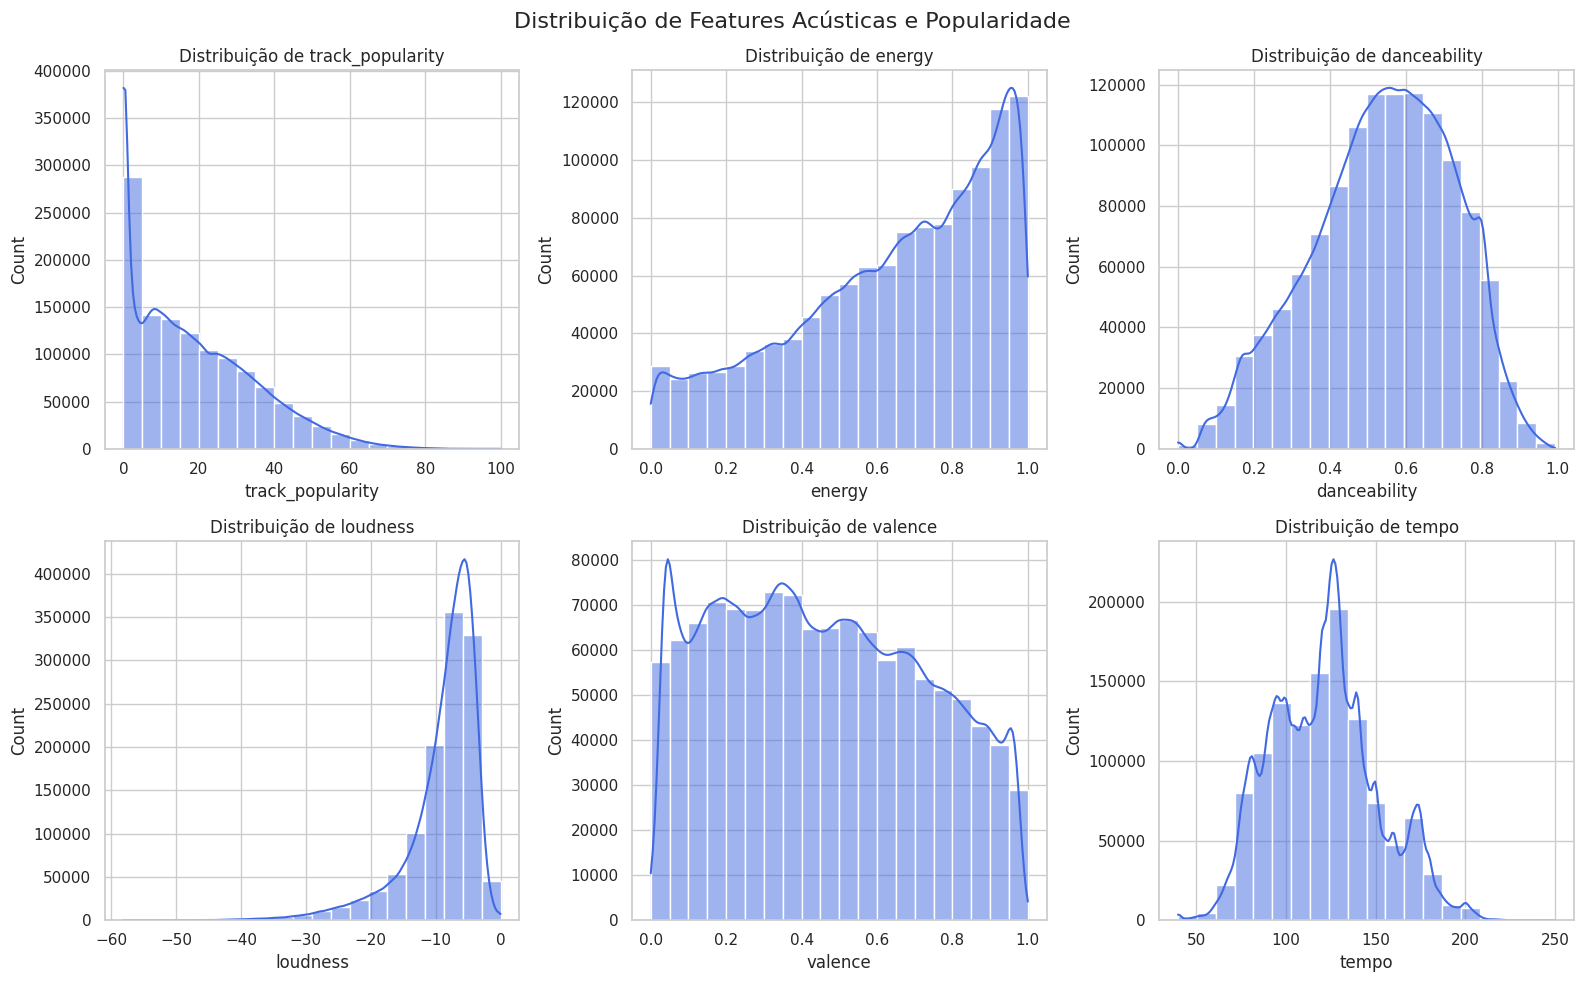

In [3]:
# Criar uma figura com múltiplos gráficos
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
fig.suptitle('Distribuição de Features Acústicas e Popularidade', fontsize=16)

# Plotar histogramas para cada feature selecionada
for i, feature in enumerate(features):
    row = i // 3
    col = i % 3
    sns.histplot(df[feature], bins=20, kde=True, ax=axes[row, col], color='royalblue')
    axes[row, col].set_title(f'Distribuição de {feature}')

plt.tight_layout()
plt.show()

4. Matriz de Correlação (Análise Bivariada)
Nesta amostra reduzida, a popularidade da faixa tem uma correlação positiva moderada de 0.24 com a característica de ser dançante (danceability), e uma correlação negativa de -0.09 com a valência (valence). O bloco abaixo gera o mapa de calor visualizando a correlação de Pearson entre todas as variáveis escolhidas.

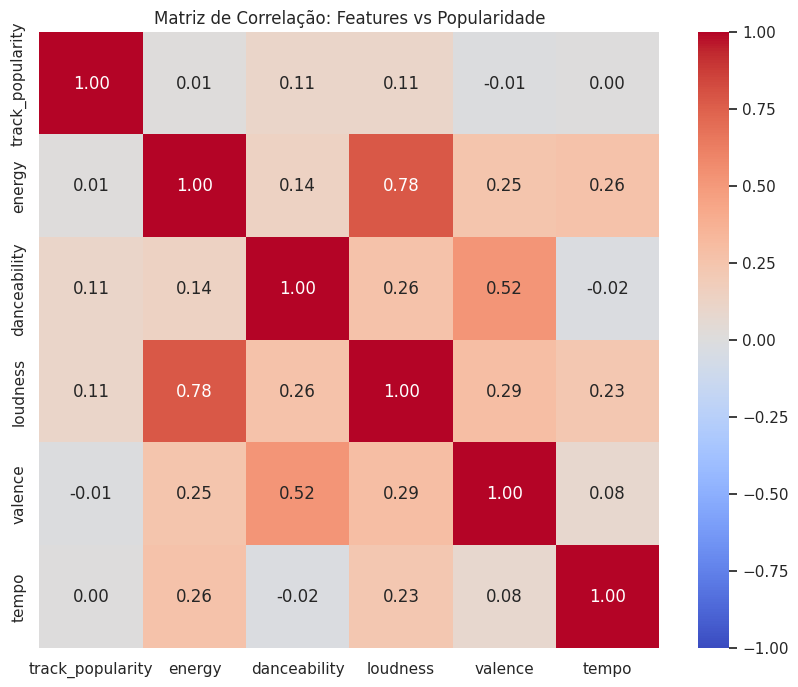

In [4]:
# Calcular a matriz de correlação de Pearson
corr_matrix = df[features].corr()

# Plotar o mapa de calor (Heatmap)
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", vmin=-1, vmax=1)
plt.title('Matriz de Correlação: Features vs Popularidade')
plt.show()

In [5]:
# importação das bibliotecas necessárias
!pip install pandas numpy matplotlib seaborn

import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook") 
pd.set_option("display.max_columns", 100) 
pd.set_option("display.max_rows", 200)
pd.set_option("display.float_format", "{:,.3f}".format) 
plt.rcParams["figure.dpi"] = 110 

DATA_PATH = "../data/raw/spotify_train.csv" 
SEED = 42
TARGET = "track_popularity" 



[notice] A new release of pip is available: 23.0.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
